# Swendsen–Wang sampler for the planar Ising random current (Lis, Lemma 3.1)

Simple current with boundary set $A$ (sources on the outer face), sampled in the dual: signs on faces, odd edges = edges between faces of different sign.
Weight: $P(\omega)\propto\prod_{\omega_1}x_e\prod_{\omega_2}(1-y_e)\prod_{E\setminus\omega}y_e$, $x_e=\tanh J_e$, $y_e=1/\cosh J_e$.

In [1]:
import csv
import itertools
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from matplotlib.lines import Line2D
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

SEED = 2024
J_CRIT = 0.5 * np.log(1 + np.sqrt(2))

## 1. Sampler

In [2]:
def grid_graph(R, C, A=(), border_sign=-1):
    # boundary vertices in clockwise order
    cycle = [(0, j) for j in range(C)] + [(i, C - 1) for i in range(1, R)] \
        + [(R - 1, j) for j in range(C - 2, -1, -1)] + [(i, 0) for i in range(R - 2, 0, -1)]
    L = len(cycle)
    pos = {v: k for k, v in enumerate(cycle)}
    A = sorted(set(A), key=lambda v: pos[v])
    if len(A) % 2:
        raise ValueError("A must have an even number of vertices")
    n_outer = max(1, len(A))              # border sectors (1 outer face if A is empty)
    a_pos = [pos[v] for v in A]

    def sector_of_border_edge(k):
        if not A:
            return 0
        return (sum(p <= k for p in a_pos) - 1) % len(A)

    border_sector = {frozenset((cycle[k], cycle[(k + 1) % L])): sector_of_border_edge(k)
                     for k in range(L)}

    def inner(a, b):
        if a < 0 or b < 0 or a > R - 2 or b > C - 2:
            return None
        return n_outer + a * (C - 1) + b

    edges, edge_faces = [], []
    for i in range(R):
        for j in range(C):
            if j < C - 1:
                edges.append(((i, j), (i, j + 1)))
                edge_faces.append((inner(i - 1, j), inner(i, j)))
            if i < R - 1:
                edges.append(((i, j), (i + 1, j)))
                edge_faces.append((inner(i, j - 1), inner(i, j)))

    for e, (u, v) in enumerate(edges):
        f1, f2 = edge_faces[e]
        s = border_sector.get(frozenset((u, v)))
        edge_faces[e] = (s if f1 is None else f1, s if f2 is None else f2)

    n_faces = n_outer + (R - 1) * (C - 1)
    fixed_sign = np.zeros(n_faces, dtype=int)
    for k in range(n_outer):
        fixed_sign[k] = border_sign * (-1) ** k   # sectors alternate

    edges_idx = np.array([(u[0] * C + u[1], v[0] * C + v[1]) for u, v in edges])
    return edges_idx, np.array(edge_faces), n_faces, fixed_sign, n_outer


def sw_step(tau, edge_faces, n_faces, x, fixed_sign, rng):
    f1, f2 = edge_faces[:, 0], edge_faces[:, 1]
    agree = tau[f1] == tau[f2]
    bond = agree & (rng.random(len(x)) < 1.0 - x)

    adj = coo_matrix((np.ones(bond.sum()), (f1[bond], f2[bond])), shape=(n_faces, n_faces))
    n_clusters, label = connected_components(adj, directed=False)

    cluster_sign = rng.choice(np.array([-1, 1]), size=n_clusters)
    fixed = np.flatnonzero(fixed_sign != 0)
    cluster_sign[label[fixed]] = fixed_sign[fixed]
    return cluster_sign[label]


def sample_simple_current(edge_faces, n_faces, J, fixed_sign, n_samples, seed,
                          burn_in=100, thin=1):
    # returns faces (n_samples, n_faces) in {-1,+1}, and boolean omega1, omega2 (n_samples, E)
    rng = np.random.default_rng(seed)
    J = np.asarray(J, dtype=float)
    x = np.tanh(J)
    y = 1.0 / np.cosh(J)
    f1, f2 = edge_faces[:, 0], edge_faces[:, 1]

    tau = rng.choice(np.array([-1, 1]), size=n_faces)
    tau[fixed_sign != 0] = fixed_sign[fixed_sign != 0]
    for _ in range(burn_in):
        tau = sw_step(tau, edge_faces, n_faces, x, fixed_sign, rng)

    faces = np.zeros((n_samples, n_faces), dtype=int)
    omega1 = np.zeros((n_samples, len(J)), dtype=bool)
    omega2 = np.zeros((n_samples, len(J)), dtype=bool)
    for s in range(n_samples):
        for _ in range(thin):
            tau = sw_step(tau, edge_faces, n_faces, x, fixed_sign, rng)
        odd = tau[f1] != tau[f2]
        extra = (~odd) & (rng.random(len(J)) < 1.0 - y)
        faces[s], omega1[s], omega2[s] = tau, odd, extra
    return faces, omega1, omega2

### Integer currents (Poisson with rejection)

The chain works at the level of $\omega$. If the values $n_e$ are needed: given $\omega$, the $n_e$ are independent, each
Poisson$(J_e)$ conditioned on its class — odd on $\omega_1$, even and nonzero on $\omega_2$, $0$ elsewhere.
Each edge is redrawn from Poisson$(J_e)$ until it falls in its class (acceptance $e^{-J}\sinh J$ for odd, $e^{-J}(\cosh J-1)$ for even nonzero; slow only for very small $J$).

In [3]:
def sample_currents(omega1, omega2, J, seed):
    rng = np.random.default_rng(seed)
    Jf = np.broadcast_to(np.asarray(J, dtype=float), omega1.shape).reshape(-1)
    n = np.zeros(omega1.shape, dtype=np.int64)
    flat = n.reshape(-1)
    for mask, parity in ((omega1, 1), (omega2, 0)):
        todo = np.flatnonzero(mask)
        while len(todo):
            draw = rng.poisson(Jf[todo])
            ok = (draw % 2 == parity) & (draw > 0)
            flat[todo[ok]] = draw[ok]
            todo = todo[~ok]
    return n

## 2. Tests against exact enumeration

In [4]:
def odd_vertices(omega1, edges, n_vertices):
    deg = np.zeros((len(omega1), n_vertices), dtype=int)
    for e, (u, v) in enumerate(edges):
        deg[:, u] += omega1[:, e]
        deg[:, v] += omega1[:, e]
    return deg % 2 == 1


def exact_E_A(edges, n_vertices, A_idx):
    target = np.zeros(n_vertices, dtype=bool)
    target[list(A_idx)] = True
    out = []
    for bits in itertools.product([0, 1], repeat=len(edges)):
        deg = np.zeros(n_vertices, dtype=int)
        for b, (u, v) in zip(bits, edges):
            if b:
                deg[u] += 1
                deg[v] += 1
        if np.array_equal(deg % 2 == 1, target):
            out.append(bits)
    return out


def lemma31_joint(omega1_set, J):
    x, y = np.tanh(J), 1 / np.cosh(J)
    E = len(J)
    probs = {}
    for w1 in omega1_set:
        free = [e for e in range(E) if not w1[e]]
        for sub in itertools.product([0, 1], repeat=len(free)):
            w2 = [0] * E
            for e, b in zip(free, sub):
                w2[e] = b
            p = 1.0
            for e in range(E):
                p *= x[e] if w1[e] else ((1 - y[e]) if w2[e] else y[e])
            probs[(tuple(w1), tuple(w2))] = p
    Z = sum(probs.values())
    return {k: v / Z for k, v in probs.items()}


def tv(p, q):
    return 0.5 * sum(abs(p.get(k, 0) - q.get(k, 0)) for k in set(p) | set(q))


def empirical(o1, o2=None):
    d = {}
    for s in range(len(o1)):
        k = tuple(int(t) for t in o1[s]) if o2 is None else \
            (tuple(int(t) for t in o1[s]), tuple(int(t) for t in o2[s]))
        d[k] = d.get(k, 0) + 1
    return {k: v / len(o1) for k, v in d.items()}

In [5]:
rng = np.random.default_rng(0)
R, C = 3, 3
cases = {
    "A = empty": ([], -1),
    "A = 2 opposite corners": ([(0, 0), (2, 2)], -1),
    "A = 4 corners": ([(0, 0), (0, 2), (2, 2), (2, 0)], -1),
    "A = 2 edge midpoints (border sign +)": ([(0, 1), (1, 2)], +1),
    "A = 6 border vertices": ([(0, 0), (0, 1), (0, 2), (1, 2), (2, 1), (1, 0)], -1),
}
for name, (A, s0) in cases.items():
    edges, ef, nf, fixed, n_out = grid_graph(R, C, A, border_sign=s0)
    J = rng.uniform(0.2, 1.2, size=len(edges))
    A_idx = [i * C + j for i, j in A]
    faces, o1, o2 = sample_simple_current(ef, nf, J, fixed, n_samples=40000, seed=1)

    parity_ok = np.all(odd_vertices(o1, edges, R * C) == np.isin(np.arange(R * C), A_idx))
    differ_ok = np.array_equal(o1, faces[:, ef[:, 0]] != faces[:, ef[:, 1]])
    E_A = exact_E_A(edges, R * C, A_idx)
    x = np.tanh(J)
    w = np.array([np.prod(np.where(np.array(b, bool), x, 1.0)) for b in E_A])
    exact = {b: wi / w.sum() for b, wi in zip(E_A, w)}
    print(f"{name}: |E_A|={len(E_A)}, odd set == A: {bool(parity_ok)}, "
          f"odd <=> faces differ: {bool(differ_ok)}, support == E_A: {set(empirical(o1)) == set(exact)}, "
          f"TV(omega_1) = {tv(empirical(o1), exact):.4f}")

A = empty: |E_A|=16, odd set == A: True, odd <=> faces differ: True, support == E_A: True, TV(omega_1) = 0.0073
A = 2 opposite corners: |E_A|=16, odd set == A: True, odd <=> faces differ: True, support == E_A: True, TV(omega_1) = 0.0097
A = 4 corners: |E_A|=16, odd set == A: True, odd <=> faces differ: True, support == E_A: True, TV(omega_1) = 0.0102
A = 2 edge midpoints (border sign +): |E_A|=16, odd set == A: True, odd <=> faces differ: True, support == E_A: True, TV(omega_1) = 0.0113
A = 6 border vertices: |E_A|=16, odd set == A: True, odd <=> faces differ: True, support == E_A: True, TV(omega_1) = 0.0124


In [6]:
A = [(0, 0), (1, 2)]
edges, ef, nf, fixed, n_out = grid_graph(2, 3, A, border_sign=-1)
J = rng.uniform(0.2, 1.2, size=len(edges))
exact = lemma31_joint(exact_E_A(edges, 6, [0, 5]), J)
faces, o1, o2 = sample_simple_current(ef, nf, J, fixed, n_samples=150000, seed=2)
print(f"2x3, A = 2 corners: #states = {len(exact)}, TV(empirical, Lemma 3.1) = "
      f"{tv(empirical(o1, o2), exact):.4f}")

edges, ef, nf, fixed, n_out = grid_graph(3, 3, [(0, 0), (2, 2)])
J = rng.uniform(0.2, 1.2, size=len(edges))
a = sample_simple_current(ef, nf, J, fixed, 500, seed=7)
b = sample_simple_current(ef, nf, J, fixed, 500, seed=7)
c = sample_simple_current(ef, nf, J, fixed, 500, seed=8)
print("same seed -> identical:", all((u == v).all() for u, v in zip(a, b)))
print("different seed -> different:", not all((u == v).all() for u, v in zip(a, c)))

2x3, A = 2 corners: #states = 52, TV(empirical, Lemma 3.1) = 0.0069
same seed -> identical: True
different seed -> different: True


### Integer currents against global Poisson rejection

In [7]:
def poisson_global_rejection(edges, n_vertices, A_idx, J, n_samples, rng, chunk=400000):
    # independent Poisson(J_e) currents, kept only if the set of sources is exactly A
    target = np.zeros(n_vertices, dtype=int)
    target[list(A_idx)] = 1
    kept, tried = [], 0
    while sum(len(k) for k in kept) < n_samples:
        n = rng.poisson(J, size=(chunk, len(J)))
        par = np.zeros((chunk, n_vertices), dtype=int)
        for e, (u, v) in enumerate(edges):
            par[:, u] += n[:, e] % 2
            par[:, v] += n[:, e] % 2
        kept.append(n[((par % 2) == target).all(axis=1)])
        tried += chunk
    return np.concatenate(kept)[:n_samples], sum(len(k) for k in kept) / tried


def edge_marginals(n, kmax=6):
    return np.array([(n == k).mean(0) for k in range(kmax + 1)])


def source_set_ok(n, edges, n_vertices, A_idx):
    deg = np.zeros((len(n), n_vertices), dtype=int)
    for e, (u, v) in enumerate(edges):
        deg[:, u] += n[:, e]
        deg[:, v] += n[:, e]
    target = np.isin(np.arange(n_vertices), A_idx)
    return bool(np.all((deg % 2 == 1) == target))

In [8]:
rng = np.random.default_rng(21)
A = [(0, 0), (1, 2)]
A_idx = [0, 5]
edges, ef, nf, fixed, _ = grid_graph(2, 3, A)
J = rng.uniform(0.2, 1.0, size=len(edges))
N = 60000

g1, acc = poisson_global_rejection(edges, 6, A_idx, J, N, rng)
g2, _ = poisson_global_rejection(edges, 6, A_idx, J, N, rng)
faces, o1, o2 = sample_simple_current(ef, nf, J, fixed, N, seed=4)
s = sample_currents(o1, o2, J, seed=5)

print(f"simple current, 2x3, A = 2 corners (global rejection acceptance {acc:.3f})")
print("sources of sampled currents == A:", source_set_ok(s, edges, 6, A_idx))
print("omega(n) == (omega_1, omega_2):", np.array_equal(s % 2 == 1, o1) and np.array_equal((s > 0) & (s % 2 == 0), o2))
print(f"TV of the full integer law: global vs global' = {tv(empirical(g1), empirical(g2)):.4f}, "
      f"global vs chain+values = {tv(empirical(g1), empirical(s)):.4f}")
print(f"max |P(n_e = k) difference| (k<=6): global vs global' = {np.abs(edge_marginals(g1) - edge_marginals(g2)).max():.4f}, "
      f"global vs chain+values = {np.abs(edge_marginals(g1) - edge_marginals(s)).max():.4f}")

simple current, 2x3, A = 2 corners (global rejection acceptance 0.027)
sources of sampled currents == A: True
omega(n) == (omega_1, omega_2): True
TV of the full integer law: global vs global' = 0.0330, global vs chain+values = 0.0339
max |P(n_e = k) difference| (k<=6): global vs global' = 0.0052, global vs chain+values = 0.0090


## 3. Running a case and drawing it

In [9]:
def run_case(R, C, A, border_sign=-1, J0=J_CRIT, seed=SEED, burn_in=500, with_values=False):
    edges, edge_faces, n_faces, fixed, n_outer = grid_graph(R, C, A, border_sign)
    J = np.full(len(edges), J0)
    faces, o1, o2 = sample_simple_current(edge_faces, n_faces, J, fixed, 1, seed, burn_in)
    tau, odd, in2 = faces[0], o1[0], o2[0]

    assert np.array_equal(odd, tau[edge_faces[:, 0]] != tau[edge_faces[:, 1]])
    deg = np.bincount(edges[odd].ravel(), minlength=R * C)
    assert sorted(divmod(int(v), C) for v in np.flatnonzero(deg % 2)) == sorted(A)
    case = dict(R=R, C=C, A=list(A), edges=edges, edge_faces=edge_faces, n_outer=n_outer,
                tau=tau, odd=odd, in2=in2)
    if with_values:
        case["n"] = sample_currents(odd, in2, J, np.random.SeedSequence(seed).spawn(1)[0])
    return case


def print_faces(case):
    tau, n_outer, R, C = case["tau"], case["n_outer"], case["R"], case["C"]
    sign = lambda s: "+" if s > 0 else "-"
    print("border sectors:", " ".join(sign(s) for s in tau[:n_outer]))
    print("inner faces (rows top->bottom, columns left->right):")
    for row in tau[n_outer:].reshape(R - 1, C - 1):
        print(" ".join(sign(s) for s in row))
    print(f"odd edges (omega_1): {case['odd'].sum()},  even nonzero edges (omega_2): {case['in2'].sum()}")


def odd_edge_list(case):
    C = case["C"]
    return [(divmod(int(u), C), divmod(int(v), C)) for u, v in case["edges"][case["odd"]]]


def joined_groups(case):
    R, C, edges = case["R"], case["C"], case["edges"][case["odd"]]
    adj = coo_matrix((np.ones(len(edges)), (edges[:, 0], edges[:, 1])), shape=(R * C, R * C))
    _, comp = connected_components(adj, directed=False)
    groups = {}
    for v in case["A"]:
        groups.setdefault(comp[v[0] * C + v[1]], []).append(v)
    return list(groups.values())


def save_csv(case, path):
    C, tau, ef = case["C"], case["tau"], case["edge_faces"]
    with open(path, "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["edge", "vertex1(i,j)", "vertex2(i,j)", "face1", "face2",
                    "sign1", "sign2", "odd(faces differ)", "in_omega2"])
        for e, (u, v) in enumerate(case["edges"]):
            f1, f2 = ef[e]
            w.writerow([e, divmod(int(u), C), divmod(int(v), C), int(f1), int(f2),
                        int(tau[f1]), int(tau[f2]), int(case["odd"][e]), int(case["in2"][e])])

In [10]:
INK, INK2, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
COL = {+1: "#2a78d6", -1: "#eb6834"}


def draw(ax, case, glyphs=True):
    R, C, A = case["R"], case["C"], case["A"]
    edges, ef, n_outer = case["edges"], case["edge_faces"], case["n_outer"]
    tau, odd, in2 = case["tau"], case["odd"], case["in2"]
    inner = tau[n_outer:].reshape(R - 1, C - 1)
    ax.set_facecolor(SURFACE)

    for a in range(R - 1):
        for b in range(C - 1):
            s = inner[a, b]
            ax.add_patch(Rectangle((b, -(a + 1)), 1, 1, facecolor=COL[s], alpha=0.30, lw=0))
            if glyphs:
                ax.text(b + 0.5, -(a + 0.5), "+" if s > 0 else "−", ha="center",
                        va="center", fontsize=7, color=INK2)

    lo, hi = 0.12, 0.34
    for e in range(len(edges)):          # border sectors as strips outside the grid
        f1, f2 = ef[e]
        sec = f1 if f1 < n_outer else (f2 if f2 < n_outer else None)
        if sec is None:
            continue
        (i1, j1), (i2, j2) = divmod(int(edges[e, 0]), C), divmod(int(edges[e, 1]), C)
        if i1 == i2 == 0:
            rect = (min(j1, j2), lo, 1, hi - lo)
        elif i1 == i2 == R - 1:
            rect = (min(j1, j2), -(R - 1) - hi, 1, hi - lo)
        elif j1 == j2 == 0:
            rect = (-hi, -max(i1, i2), hi - lo, 1)
        else:
            rect = (C - 1 + lo, -max(i1, i2), hi - lo, 1)
        ax.add_patch(Rectangle(rect[:2], rect[2], rect[3], facecolor=COL[tau[sec]], alpha=0.9, lw=0))

    for e in range(len(edges)):
        u, v = divmod(int(edges[e, 0]), C), divmod(int(edges[e, 1]), C)
        xs, ys = [u[1], v[1]], [-u[0], -v[0]]
        if odd[e]:
            ax.plot(xs, ys, color=INK, lw=3.0, solid_capstyle="round", zorder=4)
        elif in2[e]:
            ax.plot(xs, ys, color=INK2, lw=1.4, ls=(0, (3, 2)), zorder=3)
        else:
            ax.plot(xs, ys, color="#c9c8c3", lw=0.7, zorder=2)

    ii, jj = np.meshgrid(range(R), range(C), indexing="ij")
    ax.scatter(jj.ravel(), -ii.ravel(), s=4, color=INK2, zorder=5)
    if A:
        ax.scatter([v[1] for v in A], [-v[0] for v in A], s=110, facecolor=SURFACE,
                   edgecolor=INK, linewidth=2, zorder=6)
    ax.set_aspect("equal")
    ax.set_xlim(-0.6, C - 0.4)
    ax.set_ylim(-(R - 1) - 0.6, 0.6)
    ax.axis("off")


def legend_handles():
    return [
        Patch(facecolor=COL[+1], alpha=0.5, label="face sign +"),
        Patch(facecolor=COL[-1], alpha=0.5, label="face sign −  (outer strips = border sectors)"),
        Line2D([0], [0], color=INK, lw=3, label="odd edge: faces differ (ω₁)"),
        Line2D([0], [0], color=INK2, lw=1.4, ls=(0, (3, 2)), label="even nonzero edge (ω₂)"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor=SURFACE, markeredgecolor=INK,
               markeredgewidth=2, markersize=9, label="A (odd-degree vertices)"),
    ]


def plot_case(case, title):
    fig, ax = plt.subplots(figsize=(9, 9), dpi=100)
    fig.patch.set_facecolor(SURFACE)
    draw(ax, case)
    ax.legend(handles=legend_handles(), loc="upper center", bbox_to_anchor=(0.5, -0.01),
              ncol=3, frameon=False, fontsize=8, labelcolor=INK2)
    ax.set_title(title, fontsize=11, color=INK)
    plt.show()


def plot_overview(results, title):
    fig, axes = plt.subplots(1, 3, figsize=(25, 12.8), dpi=80)
    fig.patch.set_facecolor(SURFACE)
    for ax, (label, cs) in zip(axes.ravel(), results.items()):
        draw(ax, cs, glyphs=False)
        ax.set_title(f"{label}\n|ω₁| = {cs['odd'].sum()},  |ω₂| = {cs['in2'].sum()}",
                     fontsize=25, color=INK)
    fig.legend(handles=legend_handles(), loc="lower center", ncol=5, frameon=False,
               fontsize=20, labelcolor=INK2)
    fig.suptitle(title, fontsize=25, color=INK)
    fig.tight_layout(rect=(0, 0.04, 1, 0.97))
    fig.subplots_adjust(hspace=0.3)
    plt.show()

## 4. One sample: 20×20 grid, A = four corners, negative border

border sectors: - + - +
inner faces (rows top->bottom, columns left->right):
+ - - - - - - - - - - - - - - + + + +
+ + - - - - - - - - - - - - - - + + +
- + - + + + - - + - - - - - - - + + +
+ + + + + + - + + + - - - - + + + + +
+ + + + + - - + + + + + - - + + + + +
+ + + + + - - - + + + + - - - - - + -
+ + + + + + - + + + + + + + - - + + -
+ + + + + + + + + + + + + + + + + + +
+ + + + + + + + + + + + + + + + + + +
+ + + + + + + + + + + + + + + + + + +
+ - + + + + + + + + + + + + + + + + +
+ + + + + + + + + + + + + + + + + + +
+ + + - + + + + + + + + + + + + + + +
+ - - - - + + + + + + + + + + + + + +
+ + - - - + + + + + + + + + + + + + +
- + + + + + + + + + + + - + + + - + +
+ + + + + + - - + + + + - - - - - + +
+ + + + + - - - - - - - - - - - - + +
+ + - - - - - - - - - - - - - - - - -
odd edges (omega_1): 120,  even nonzero edges (omega_2): 59
A vertices joined through omega_1: [[(0, 0), (0, 19)], [(19, 19), (19, 0)]]
first odd edges: [((0, 0), (0, 1)), ((0, 1), (1, 1)), ((0, 15), (

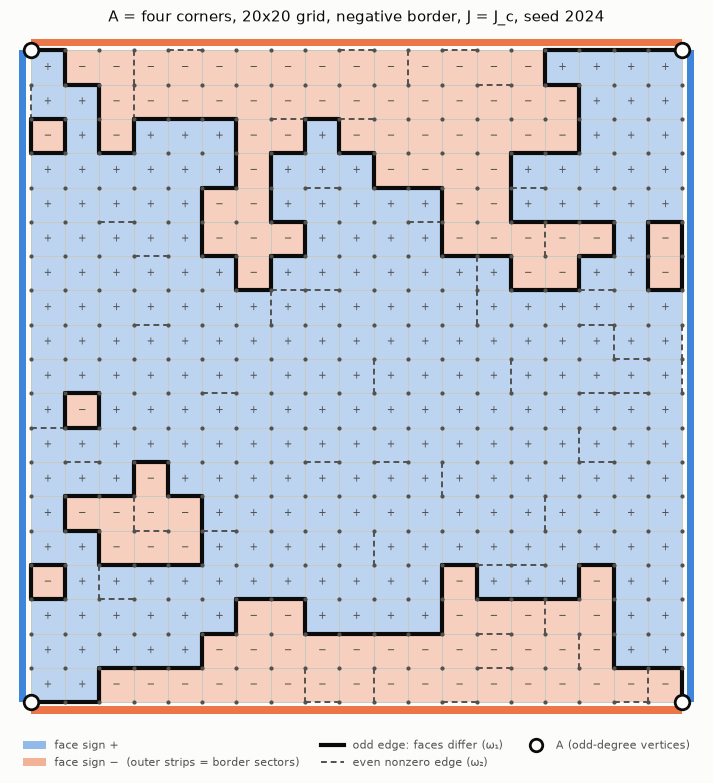

In [11]:
R = C = 20
corners = [(0, 0), (0, C - 1), (R - 1, C - 1), (R - 1, 0)]
case = run_case(R, C, corners)
print_faces(case)
print("A vertices joined through omega_1:", joined_groups(case))
print("first odd edges:", odd_edge_list(case)[:6], "...")
plot_case(case, f"A = four corners, {R}x{C} grid, negative border, J = J_c, seed {SEED}")

Same sample with the integer values $n_e$ (drawn given $\omega$):

In [12]:
case_v = run_case(R, C, corners, with_values=True)
n = case_v["n"]
print("n_e value counts (0, 1, 2, ...):", np.bincount(n).tolist())
deg = np.bincount(case_v["edges"].ravel(), weights=np.repeat(n, 2), minlength=R * C)
print("sources of n:", sorted(divmod(int(v), C) for v in np.flatnonzero(deg % 2)))
print("odd <=> omega_1, even nonzero <=> omega_2:", np.array_equal(n % 2 == 1, case_v["odd"])
      and np.array_equal((n > 0) & (n % 2 == 0), case_v["in2"]))

n_e value counts (0, 1, 2, ...): [581, 112, 58, 8, 1]
sources of n: [(0, 0), (0, 19), (19, 0), (19, 19)]
odd <=> omega_1, even nonzero <=> omega_2: True


## 5. Different A sets, same seed, same negative border

The first border sector (starting at the first A vertex clockwise from the top-left corner) is negative and the sectors alternate. For $A=\emptyset$ the whole border is one negative face.

In [13]:
mid_r, mid_c = R // 2, C // 2
CASES_test = {
    "A = empty (whole border negative)": [],
    "A = {(0,0), (19,19)}  (diagonal extremes)": [(0, 0), (R - 1, C - 1)],
    "A = {(0,0), (0,19)}  (two adjacent corners)": [(0, 0), (0, C - 1)],
    "A = {(0,10), (19,10)}  (midpoints of opposite sides)": [(0, mid_c), (R - 1, mid_c)],
    "A = four corners": corners,
    "A = corners + side midpoints (8 vertices)":
        corners + [(0, mid_c), (mid_r, C - 1), (R - 1, mid_c), (mid_r, 0)],
}
CASES = {
    "A = empty (whole border negative)": [],
    "A = {(0,0), (19,19)}  (diagonal extremes)": [(0, 0), (R - 1, C - 1)],
    "A = corners + side midpoints (8 vertices)":
        corners + [(0, mid_c), (mid_r, C - 1), (R - 1, mid_c), (mid_r, 0)],
}

results = {label: run_case(R, C, A) for label, A in CASES.items()}
for label, cs in results.items():
    print(f"{label}: |omega_1| = {cs['odd'].sum()}, |omega_2| = {cs['in2'].sum()}"
          + (f", joined: {joined_groups(cs)}" if cs["A"] else ""))

A = empty (whole border negative): |omega_1| = 36, |omega_2| = 66
A = {(0,0), (19,19)}  (diagonal extremes): |omega_1| = 142, |omega_2| = 61, joined: [[(0, 0), (19, 19)]]
A = corners + side midpoints (8 vertices): |omega_1| = 150, |omega_2| = 70, joined: [[(0, 0), (19, 10)], [(0, 19), (0, 10)], [(19, 19), (10, 19)], [(19, 0), (10, 0)]]


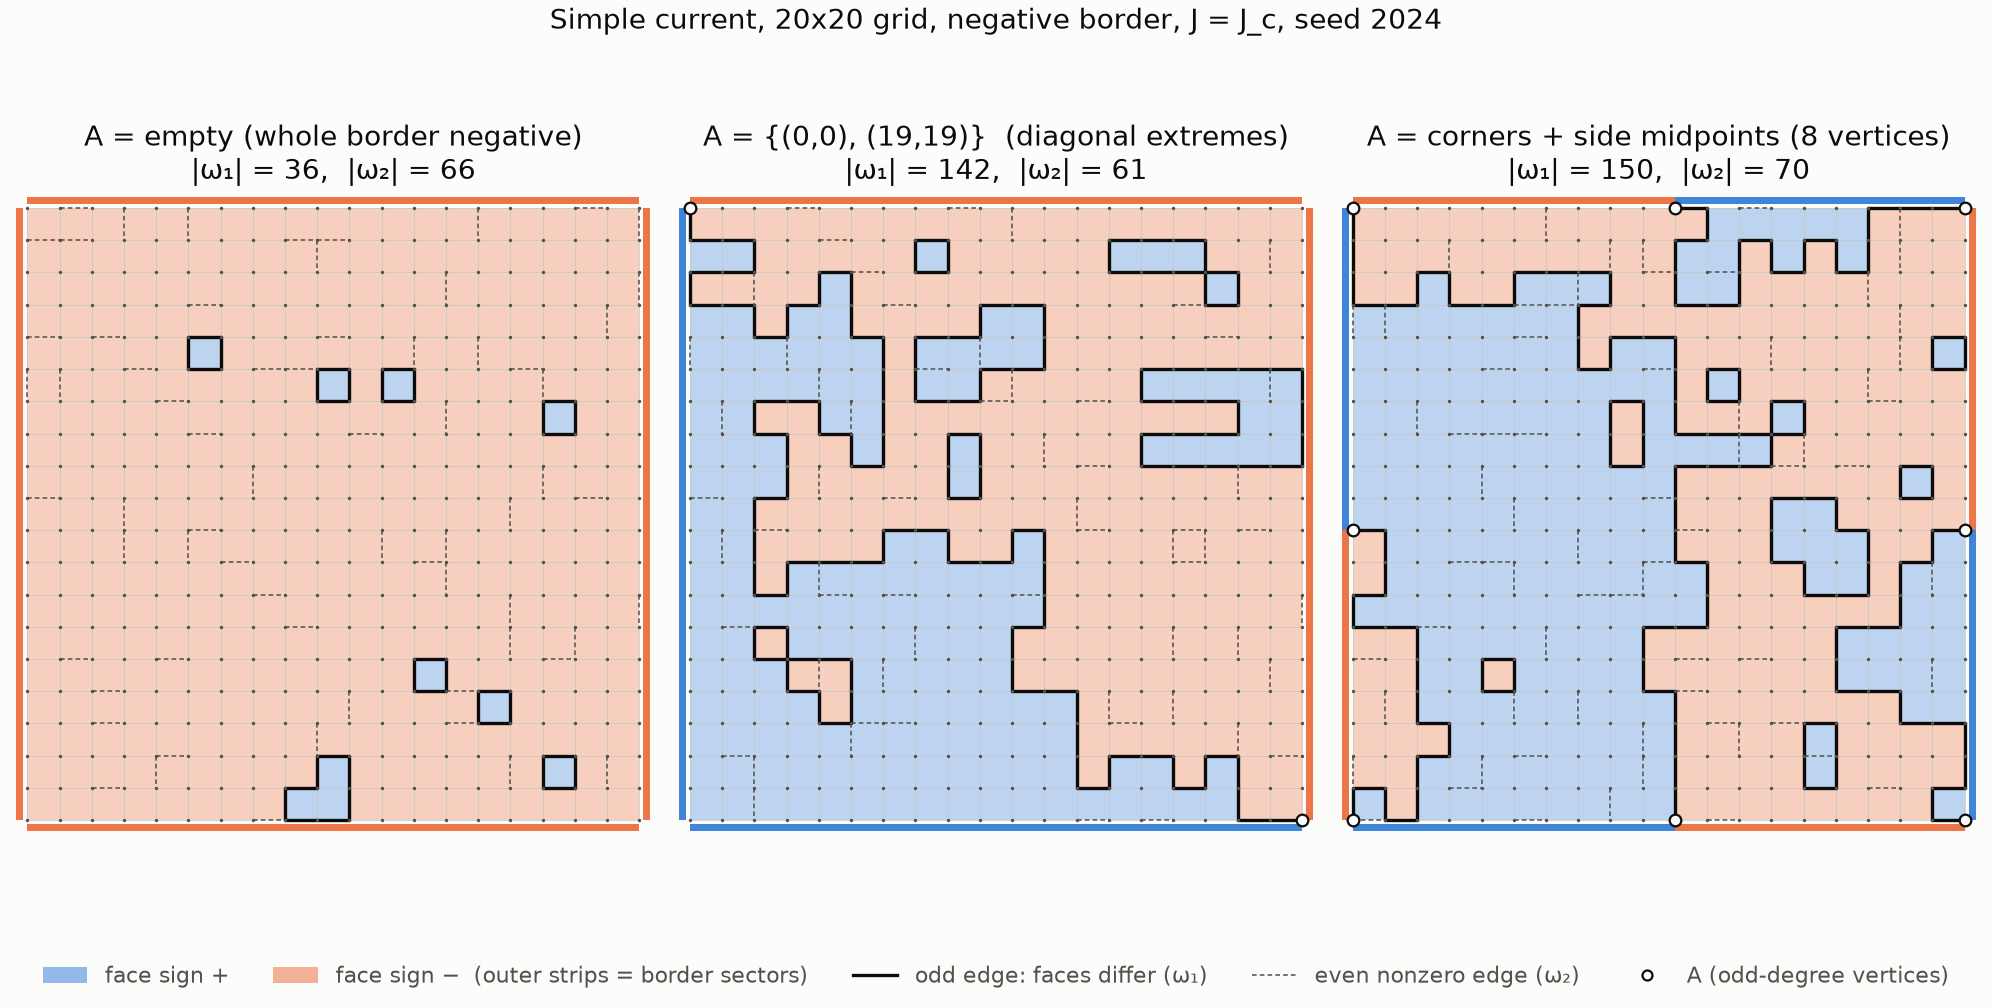

In [14]:
plot_overview(results, f"Simple current, {R}x{C} grid, negative border, J = J_c, seed {SEED}")

Diagonal extremes, with the face signs and the odd-edge table:

border sectors: - +
inner faces (rows top->bottom, columns left->right):
- - - - - - - - - - - - - - - - - - -
+ + - - - - - + - - - - - + + + - - -
- - - - + - - - - - - - - - - - + - -
+ + - + + - - - - + + - - - - - - - -
+ + + + + + - + + + + - - - - - - - -
+ + + + + + - + + - - - - - + + + + +
+ + - - + + - - - - - - - - - - - + +
+ + + - - + - - + - - - - - + + + + +
+ + + - - - - - + - - - - - - - - - -
+ + - - - - - - - - - - - - - - - - -
+ + - - - - + + - - + - - - - - - - -
+ + - + + + + + + + + - - - - - - - -
+ + + + + + + + + + + - - - - - - - -
+ + - + + + + + + + - - - - - - - - -
+ + + - - + + + + + - - - - - - - - -
+ + + + - + + + + + + + - - - - - - -
+ + + + + + + + + + + + - - - - - - -
+ + + + + + + + + + + + - + + - + - -
+ + + + + + + + + + + + + + + + + - -
odd edges (omega_1): 142,  even nonzero edges (omega_2): 61


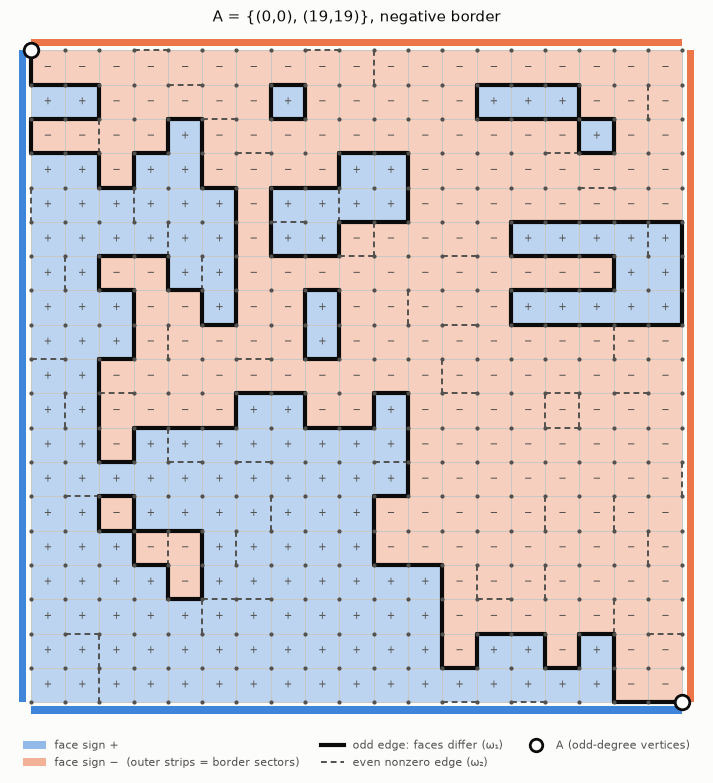

In [15]:
diag = results["A = {(0,0), (19,19)}  (diagonal extremes)"]
print_faces(diag)
plot_case(diag, "A = {(0,0), (19,19)}, negative border")
save_csv(diag, "diagonal_edges.csv")

## 6. Double random current

$n=n_1+n_2$ with $n_1\in\Omega_A$ and $n_2\in\Omega_\emptyset$ independent. Each one is sampled with the dual chain above
($\tau_1$: alternating border sectors, $\tau_2$: one border face), and $\omega(n)$ only needs $\omega(n_1),\omega(n_2)$:

$\omega_1=\omega_1^{(1)}\,\triangle\,\omega_1^{(2)}$, $\quad\omega_1\cup\omega_2=\big(\omega_1^{(1)}\cup\omega_2^{(1)}\big)\cup\big(\omega_1^{(2)}\cup\omega_2^{(2)}\big)$.

On faces, $\omega_1$ is the set of edges between faces of different sign of $\sigma=\tau_1\tau_2$.
Theorem 3.2: $P(\omega)\propto|\mathcal E_\emptyset(\omega)|\prod_{\omega_1}x_e\prod_{\omega_2}x_e^2\prod_{E\setminus\omega}(1-x_e^2)$, with $|\mathcal E_\emptyset(\omega)|=2^{|\omega|-|V(\omega)|+k(\omega)}$.

In [16]:
def double_current_grid(R, C, A, J, n_samples, seed, border_sign=-1, burn_in=100, thin=1, with_values=False):
    edges, ef_A, nf_A, fix_A, nout_A = grid_graph(R, C, A, border_sign)
    _, ef_0, nf_0, fix_0, _ = grid_graph(R, C, [], border_sign)
    J = np.broadcast_to(np.asarray(J, dtype=float), (len(edges),)).copy()

    s1, s2, s3, s4 = np.random.SeedSequence(seed).spawn(4)      # s1, s2: the two chains; s3, s4: values
    tau1, a1, b1 = sample_simple_current(ef_A, nf_A, J, fix_A, n_samples, s1, burn_in, thin)
    tau2, a2, b2 = sample_simple_current(ef_0, nf_0, J, fix_0, n_samples, s2, burn_in, thin)

    omega1 = a1 ^ a2
    omega2 = (a1 | b1 | a2 | b2) & ~omega1

    sigma = tau1.copy()                                  # sigma = tau1 * tau2 on the faces of the A-graph
    sigma[:, :nout_A] *= tau2[:, [0]]
    sigma[:, nout_A:] *= tau2[:, 1:]
    sigma *= border_sign                                 # global sign: first border sector = border_sign
    out = dict(edges=edges, edge_faces=ef_A, n_outer=nout_A, omega1=omega1, omega2=omega2,
               sigma=sigma, tau1=tau1, tau2=tau2,
               omega1_A=a1, omega2_A=b1, omega1_0=a2, omega2_0=b2)
    if with_values:
        out["n1"] = sample_currents(a1, b1, J, s3)
        out["n2"] = sample_currents(a2, b2, J, s4)
        out["n"] = out["n1"] + out["n2"]
    return out


def run_double_case(R, C, A, border_sign=-1, J0=J_CRIT, seed=SEED, burn_in=500, with_values=False):
    out = double_current_grid(R, C, A, J0, 1, seed, border_sign, burn_in, with_values=with_values)
    sigma, odd, in2 = out["sigma"][0], out["omega1"][0], out["omega2"][0]
    edges, ef = out["edges"], out["edge_faces"]

    assert np.array_equal(odd, sigma[ef[:, 0]] != sigma[ef[:, 1]])
    deg = np.bincount(edges[odd].ravel(), minlength=R * C)
    assert sorted(divmod(int(v), C) for v in np.flatnonzero(deg % 2)) == sorted(A)
    case = dict(R=R, C=C, A=list(A), edges=edges, edge_faces=ef, n_outer=out["n_outer"],
                tau=sigma, odd=odd, in2=in2)
    if with_values:
        case.update(n=out["n"][0], n1=out["n1"][0], n2=out["n2"][0])
    return case


def clusters(case):
    R, C, edges = case["R"], case["C"], case["edges"][case["odd"] | case["in2"]]
    adj = coo_matrix((np.ones(len(edges)), (edges[:, 0], edges[:, 1])), shape=(R * C, R * C))
    _, label = connected_components(adj, directed=False)
    sizes = np.bincount(label[np.unique(edges)])
    return label, sizes[sizes > 0]

### Test against Theorem 3.2 (exact enumeration)

In [17]:
def n_even_subgraphs(om):
    if not om:
        return 1
    parent = {}
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a
    for u, v in om:
        parent.setdefault(u, u)
        parent.setdefault(v, v)
    for u, v in om:
        parent[find(u)] = find(v)
    k = len({find(a) for a in parent})
    return 2 ** (len(om) - len(parent) + k)


def n_even_subgraphs_brute(om):
    count = 0
    for sub in itertools.product([0, 1], repeat=len(om)):
        deg = {}
        for b, (u, v) in zip(sub, om):
            if b:
                deg[u] = deg.get(u, 0) + 1
                deg[v] = deg.get(v, 0) + 1
        count += all(d % 2 == 0 for d in deg.values())
    return count


def theorem32_law(edges, n_vertices, A_idx, J):
    x = np.tanh(J)
    E = len(edges)
    E_A = exact_E_A(edges, n_vertices, A_idx)
    law = {}
    for w1 in E_A:
        free = [e for e in range(E) if not w1[e]]
        for sub in itertools.product([0, 1], repeat=len(free)):
            w2 = [0] * E
            for e, b in zip(free, sub):
                w2[e] = b
            p = n_even_subgraphs([tuple(edges[e]) for e in range(E) if w1[e] or w2[e]])
            for e in range(E):
                p *= x[e] if w1[e] else (x[e] ** 2 if w2[e] else 1 - x[e] ** 2)
            law[(tuple(w1), tuple(w2))] = p
    W = sum(law.values())
    sum_x = lambda S: sum(np.prod(np.where(np.array(b, bool), x, 1.0)) for b in S)
    Z_A = np.prod(np.cosh(J)) * sum_x(E_A)
    Z_0 = np.prod(np.cosh(J)) * sum_x(exact_E_A(edges, n_vertices, []))
    ratio = W / (Z_A * Z_0 * np.prod(1 - x ** 2))
    return {k: v / W for k, v in law.items()}, ratio

In [18]:
rng = np.random.default_rng(5)
edges = grid_graph(2, 3)[0]
J = rng.uniform(0.2, 1.2, size=len(edges))

bad = 0
for k in range(1, 2 ** len(edges)):
    om = [tuple(edges[e]) for e in range(len(edges)) if k >> e & 1]
    bad += n_even_subgraphs(om) != n_even_subgraphs_brute(om)
print("Lemma 4.2 formula vs brute force, mismatches on all 2^7 subgraphs of the 2x3 grid:", bad)

for name, A in {"A = empty": [], "A = 2 corners": [(0, 0), (1, 2)],
                "A = 4 corners": [(0, 0), (0, 2), (1, 2), (1, 0)]}.items():
    law, ratio = theorem32_law(edges, 6, [i * 3 + j for i, j in A], J)
    out = double_current_grid(2, 3, A, J, 80000, seed=11)
    print(f"2x3, {name}: #states = {len(law)}, sum of weights / (Z^A Z^0 prod(1-x^2)) = {ratio:.6f}, "
          f"TV(empirical, Theorem 3.2) = {tv(empirical(out['omega1'], out['omega2']), law):.4f}")

Lemma 4.2 formula vs brute force, mismatches on all 2^7 subgraphs of the 2x3 grid: 0
2x3, A = empty: #states = 146, sum of weights / (Z^A Z^0 prod(1-x^2)) = 1.000000, TV(empirical, Theorem 3.2) = 0.0118
2x3, A = 2 corners: #states = 52, sum of weights / (Z^A Z^0 prod(1-x^2)) = 1.000000, TV(empirical, Theorem 3.2) = 0.0078
2x3, A = 4 corners: #states = 56, sum of weights / (Z^A Z^0 prod(1-x^2)) = 1.000000, TV(empirical, Theorem 3.2) = 0.0096


In [19]:
edges = grid_graph(3, 3)[0]
J = rng.uniform(0.2, 1.2, size=len(edges))
A = [(0, 0), (2, 2)]
law, ratio = theorem32_law(edges, 9, [0, 8], J)
p1 = sum(p * np.array(w1) for (w1, w2), p in law.items())
p2 = sum(p * np.array(w2) for (w1, w2), p in law.items())

out = double_current_grid(3, 3, A, J, 60000, seed=12)
print(f"3x3, A = 2 corners: #states = {len(law)}, weight ratio = {ratio:.6f}")
print("max |P(e in omega_1) - exact| =", np.abs(out["omega1"].mean(0) - p1).max().round(4))
print("max |P(e in omega_2) - exact| =", np.abs(out["omega2"].mean(0) - p2).max().round(4))

a = double_current_grid(3, 3, A, J, 300, seed=7)
b = double_current_grid(3, 3, A, J, 300, seed=7)
c = double_current_grid(3, 3, A, J, 300, seed=8)
print("same seed -> identical:", all((a[k] == b[k]).all() for k in ("omega1", "omega2", "sigma")))
print("different seed -> different:", not (a["omega1"] == c["omega1"]).all())

3x3, A = 2 corners: #states = 1888, weight ratio = 1.000000
max |P(e in omega_1) - exact| = 0.0043
max |P(e in omega_2) - exact| = 0.0024
same seed -> identical: True
different seed -> different: True


### Integer values of the double current against global Poisson rejection

In [20]:
rng = np.random.default_rng(22)
A = [(0, 0), (1, 2)]
A_idx = [0, 5]
edges = grid_graph(2, 3)[0]
J = rng.uniform(0.2, 1.0, size=len(edges))
N = 60000

out = double_current_grid(2, 3, A, J, N, seed=6, with_values=True)
n = out["n"]
ref = [poisson_global_rejection(edges, 6, A_idx, J, N, rng)[0] + poisson_global_rejection(edges, 6, [], J, N, rng)[0]
       for _ in range(2)]
pmf = lambda m: np.bincount(m.sum(1), minlength=40)[:40] / len(m)

print("double current, 2x3, A = 2 corners: n = n1 + n2")
print("sources of n1 == A, of n2 == empty, of n == A:", source_set_ok(out["n1"], edges, 6, A_idx),
      source_set_ok(out["n2"], edges, 6, []), source_set_ok(n, edges, 6, A_idx))
print("omega(n) == (omega_1, omega_2):", np.array_equal(n % 2 == 1, out["omega1"])
      and np.array_equal((n > 0) & (n % 2 == 0), out["omega2"]))
print(f"max |P(n_e = k) difference| (k<=6): ref vs ref' = {np.abs(edge_marginals(ref[0]) - edge_marginals(ref[1])).max():.4f}, "
      f"ref vs chain+values = {np.abs(edge_marginals(ref[0]) - edge_marginals(n)).max():.4f}")
print(f"max |pmf of sum_e n_e difference|: ref vs ref' = {np.abs(pmf(ref[0]) - pmf(ref[1])).max():.4f}, "
      f"ref vs chain+values = {np.abs(pmf(ref[0]) - pmf(n)).max():.4f}")

double current, 2x3, A = 2 corners: n = n1 + n2
sources of n1 == A, of n2 == empty, of n == A: True True True
omega(n) == (omega_1, omega_2): True
max |P(n_e = k) difference| (k<=6): ref vs ref' = 0.0056, ref vs chain+values = 0.0045
max |pmf of sum_e n_e difference|: ref vs ref' = 0.0029, ref vs chain+values = 0.0025


### 20×20 double current, same A sets, negative border

In [21]:
dres = {label: run_double_case(R, C, A) for label, A in CASES.items()}
for label, cs in dres.items():
    _, sizes = clusters(cs)
    print(f"{label}: |omega_1| = {cs['odd'].sum()}, |omega_2| = {cs['in2'].sum()}, "
          f"clusters of omega = {len(sizes)}, largest = {sizes.max()} vertices")

A = empty (whole border negative): |omega_1| = 166, |omega_2| = 88, clusters of omega = 36, largest = 77 vertices
A = {(0,0), (19,19)}  (diagonal extremes): |omega_1| = 198, |omega_2| = 106, clusters of omega = 33, largest = 138 vertices
A = corners + side midpoints (8 vertices): |omega_1| = 206, |omega_2| = 93, clusters of omega = 26, largest = 162 vertices


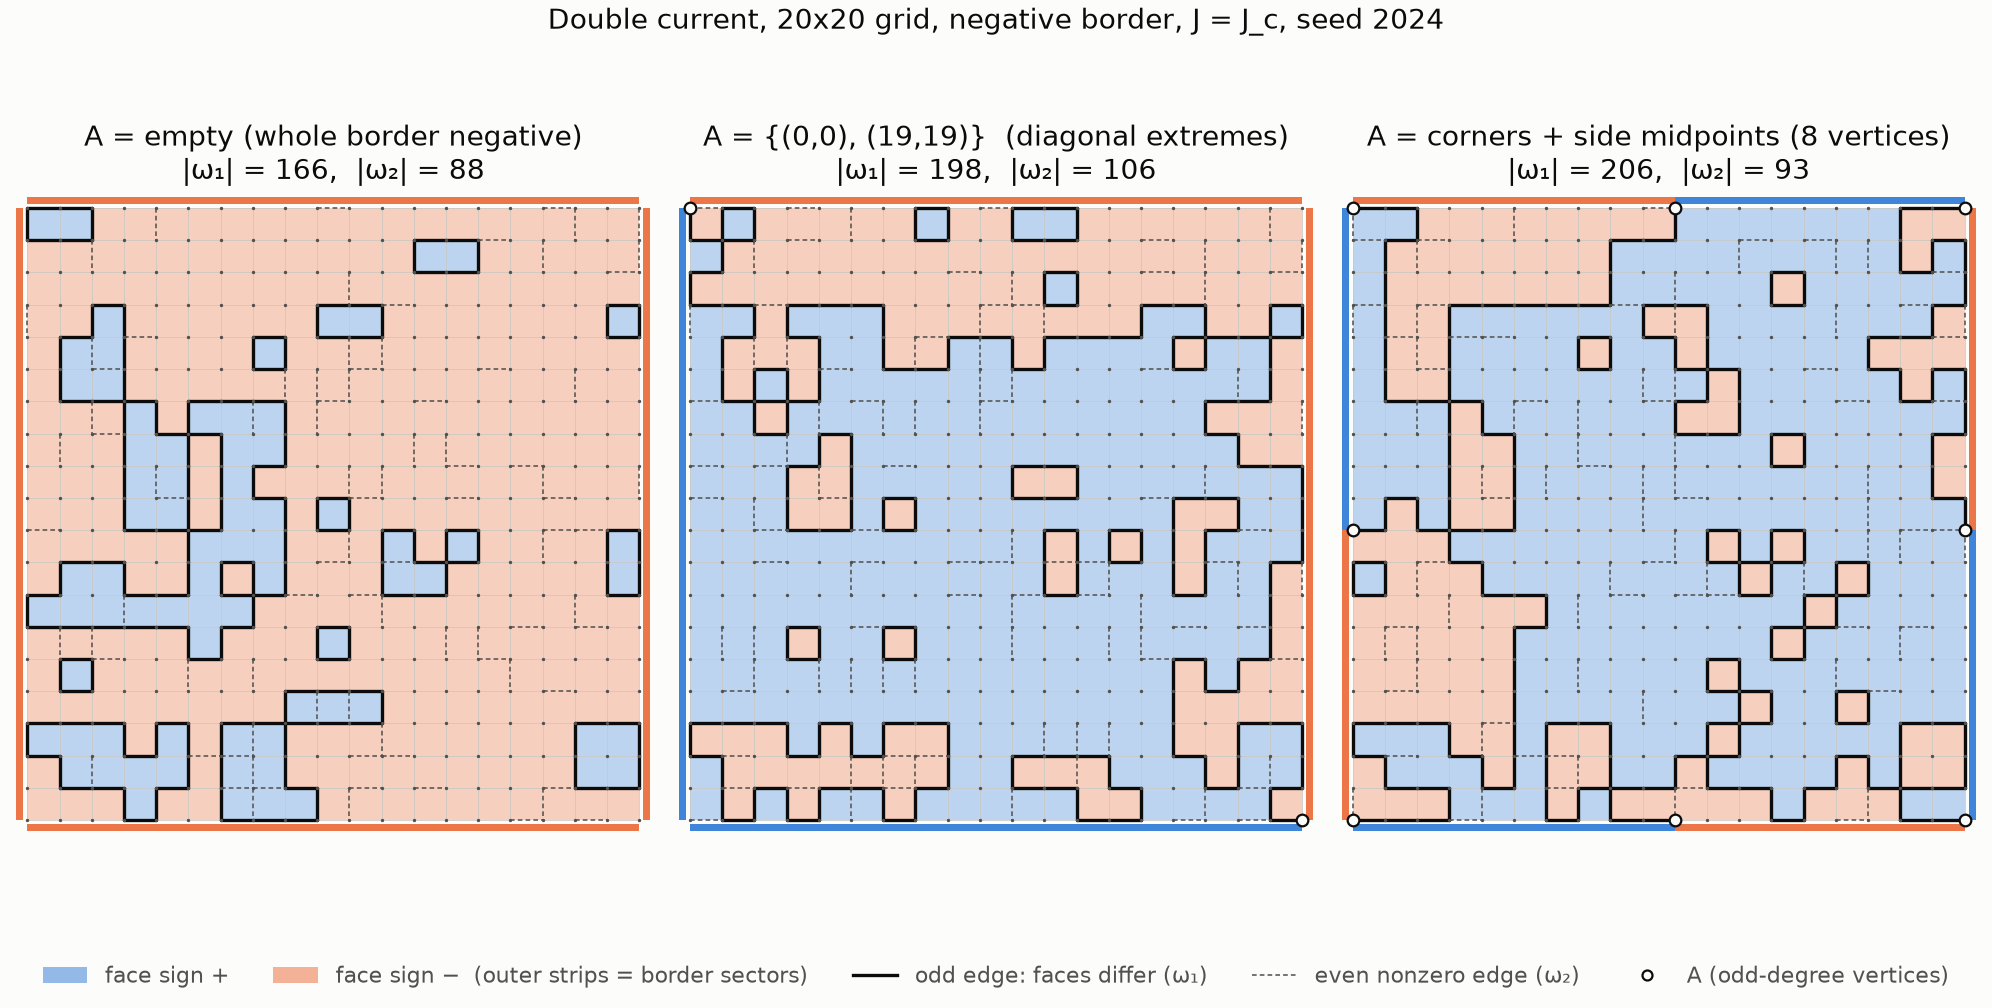

In [22]:
plot_overview(dres, f"Double current, {R}x{C} grid, negative border, J = J_c, seed {SEED}")

border sectors: - +
inner faces (rows top->bottom, columns left->right):
- + - - - - - + - - + + - - - - - - -
+ - - - - - - - - - - - - - - - - - -
- - - - - - - - - - - + - - - - - - -
+ + - + + + - - - - - - - - + + - - +
+ - - - + + - - + + - + + + + - + + -
+ - + - + + + + + + + + + + + + + + -
+ + - + + + + + + + + + + + + + - - -
+ + + + - + + + + + + + + + + + + - -
+ + + - - + + + + + - - + + + + + + +
+ + + - - + - + + + + + + + + - - + +
+ + + + + + + + + + + - + - + - + + +
+ + + + + + + + + + + - + + + - + + -
+ + + + + + + + + + + + + + + + + + -
+ + + - + + - + + + + + + + + + + + -
+ + + + + + + + + + + + + + + - + - -
+ + + + + + + + + + + + + + + - - - -
- - - + - + - - + + + + + + + - - + +
+ - - - - - - - + + - - - + + + - + +
+ - + - + + - + + + + + - - + + + + -
odd edges (omega_1): 198,  even nonzero edges (omega_2): 106


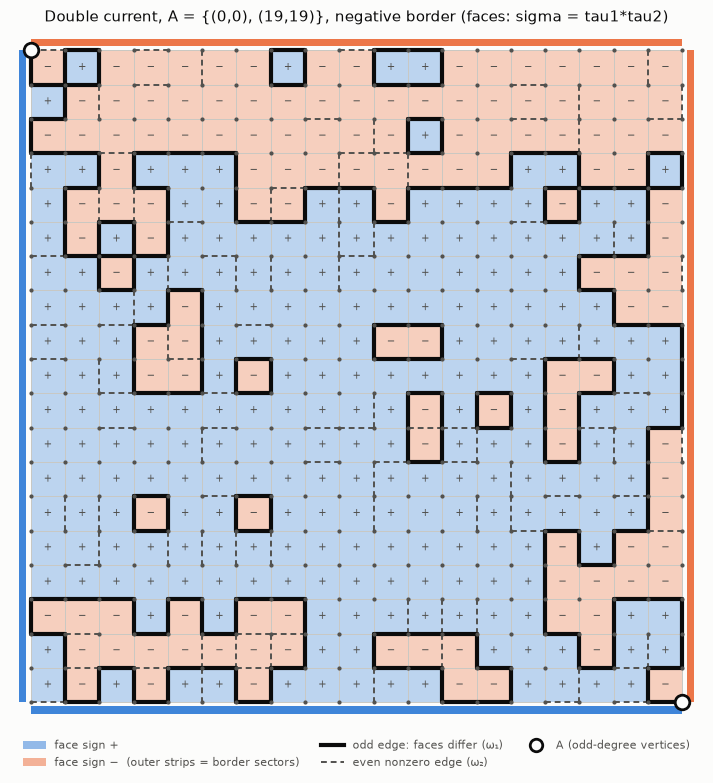

In [23]:
dd = dres["A = {(0,0), (19,19)}  (diagonal extremes)"]
print_faces(dd)
plot_case(dd, "Double current, A = {(0,0), (19,19)}, negative border (faces: sigma = tau1*tau2)")

Integer values of the double current $n=n_1+n_2$ for the diagonal case:

In [24]:
dv = run_double_case(R, C, [(0, 0), (R - 1, C - 1)], with_values=True)
n = dv["n"]
print("n_e value counts (0, 1, 2, ...):", np.bincount(n).tolist())
print("omega(n) == (omega_1, omega_2):", np.array_equal(n % 2 == 1, dv["odd"])
      and np.array_equal((n > 0) & (n % 2 == 0), dv["in2"]))

n_e value counts (0, 1, 2, ...): [456, 179, 103, 19, 3]
omega(n) == (omega_1, omega_2): True


## 7. Figures for the presentation

Samples without sources for the single-sample slides, and the three cases of sections 5 and 6 side by side. Drawn at slide size and saved in `Graficos/` (functions in `custom_packages/presentation_figures.py`).

guardado: C:\Users\gop\Desktop\wwea REMOTE\Ingenieria semestre 14\Simulacion_Estocastico\Proyecto\V4\Graficos\Corriente_Aleatoria_UnicoSample.png


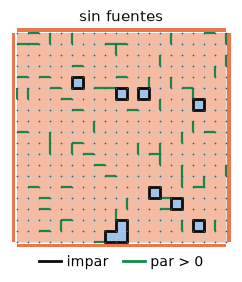

guardado: C:\Users\gop\Desktop\wwea REMOTE\Ingenieria semestre 14\Simulacion_Estocastico\Proyecto\V4\Graficos\Corriente_Aleatoria_V2.png


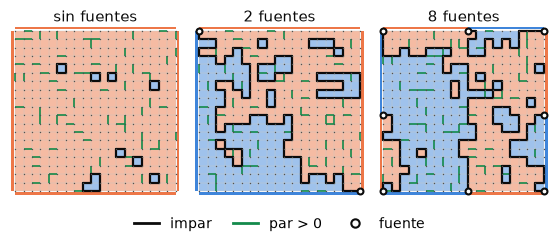

guardado: C:\Users\gop\Desktop\wwea REMOTE\Ingenieria semestre 14\Simulacion_Estocastico\Proyecto\V4\Graficos\Doble_Corriente_Aleatoria_UnicoSample.png


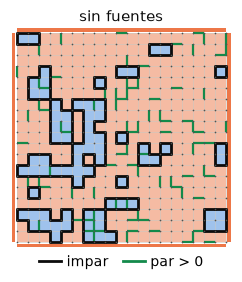

guardado: C:\Users\gop\Desktop\wwea REMOTE\Ingenieria semestre 14\Simulacion_Estocastico\Proyecto\V4\Graficos\Doble_Corriente_Aleatoria_V2.png


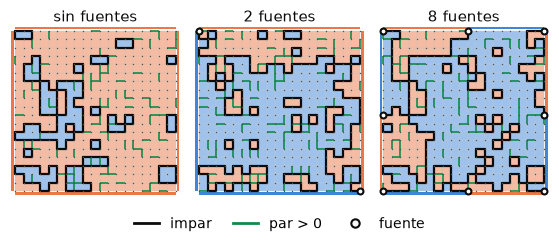

In [25]:
from custom_packages import presentation_figures as pf

R = C = 20
TITULOS = ["sin fuentes", "2 fuentes", "8 fuentes"]          # same order as CASES

# single current
caso0 = run_case(R, C, [])
pf.figura_corriente(caso0, "Corriente_Aleatoria_UnicoSample.png", titulo="sin fuentes")
pf.figura_corrientes(results, TITULOS, "Corriente_Aleatoria_V2.png")

# double current
dcaso0 = run_double_case(R, C, [])
pf.figura_corriente(dcaso0, "Doble_Corriente_Aleatoria_UnicoSample.png", titulo="sin fuentes")
pf.figura_corrientes(dres, TITULOS, "Doble_Corriente_Aleatoria_V2.png")